In [1]:
# ===========================================================================
# The acoustic-articulatory gap in the surprisal slope, from an lmer fit.
#
# This reproduces ONE panel of the trivariate figure -- "direct" -- and it is
# worth being clear about why only one.
#
# In bayes_trivariate/ the surprisal effect is decomposed through duration:
#
#     direct    surprisal -> dist, holding duration fixed
#     indirect  surprisal -> dur1 -> dist  +  surprisal -> dur2 -> dist
#     total     direct + indirect
#
# The indirect paths need a model OF duration. The lmer below has duration on
# the right-hand side as a covariate, so its surprisal coefficient is already
# duration-adjusted: it is the direct path and nothing else. There is no
# surprisal -> duration equation anywhere in it, so "indirect" and "total"
# are not estimable from this fit at all. For those, use the path model in
# bayes_trivariate/ -- it is already written.
#
# What this script does give you:
#   * emmeans / emtrends for the surprisal slope by modality
#   * the ac - art contrast of that slope, at chosen flexibility values
#   * the gap as a surface over the (flex1, flex2) plane, drawn like the
#     trivariate figure
#
# NOT EXECUTED BY ME -- no R available where I was working. Check the first
# few printed tables against your own reading of the model before trusting
# the surface.
# ===========================================================================

library(lme4)
library(lmerTest)
library(emmeans)
library(ggplot2)
library(dplyr)

# ---------------------------------------------------------------------------
# 1. Data
#
# Three things the pipeline does not do for you:
#
#   durations   are not columns; they are end - start
#   bigram      is not a column; it is phone1_phone2
#   SCALING     matters more than it looks. Raw articulatory distances average
#               ~195 and acoustic ~9.9, because the two encoders have
#               unrelated latent scales. Without scaling within modality, the
#               modality main effect and every interaction with it are
#               dominated by that arbitrary difference, and "ac - art" is not
#               interpretable. bayes_trivariate/ z-scores within modality and
#               dataset; do the same here.
# ---------------------------------------------------------------------------

UNIT <- "syllable"          # "phone" or "syllable"
CSV  <- "../../../data_processing/combine_data/results_aemri_combined.csv"

Loading required package: Matrix

Warning message:
“package ‘Matrix’ was built under R version 4.4.3”
Warning message:
“package ‘lmerTest’ was built under R version 4.4.3”

Attaching package: ‘lmerTest’


The following object is masked from ‘package:lme4’:

    lmer


The following object is masked from ‘package:stats’:

    step


Welcome to emmeans.
Caution: You lose important information if you filter this package's results.
See '? untidy'

Warning message:
“package ‘ggplot2’ was built under R version 4.4.3”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:
u  <- UNIT               # column prefix: phone1_/phone2_ or syllable1_/syllable2_
df <- read.csv(CSV)

df$u1 <- df[[paste0(u, "1")]]
df$u2 <- df[[paste0(u, "2")]]
df$u1_duration <- as.numeric(df[[paste0(u, "1_end")]] - df[[paste0(u, "1_start")]])
df$u2_duration <- as.numeric(df[[paste0(u, "2_end")]] - df[[paste0(u, "2_start")]])
df$u1_flexibility <- df[[paste0(u, "1_H_art_given_ac")]]
df$u2_flexibility <- df[[paste0(u, "2_H_art_given_ac")]]
df$u1_freq <- df[[paste0(u, "1_freq")]]
df$u2_freq <- df[[paste0(u, "2_freq")]]
df$bigram <- paste(df$u1, df$u2, sep = "_")

# the phone tables have this column; the syllable tables do not, because every
# syllable bigram spans a boundary by definition
if ("cross_syllable_boundary" %in% names(df)) {
  df <- df[!df$cross_syllable_boundary, ]
}
df <- df[df$data_space == "latent", ]

# z-score the response WITHIN modality (and within dataset, if several corpora
# are stacked in one file)
grp <- if ("dataset" %in% names(df)) c("modality", "dataset") else "modality"
df <- df %>% group_by(across(all_of(grp))) %>%
  mutate(dist = as.numeric(scale(dist))) %>% ungroup()

# moderators on a z scale, so the plot's axes are in SD units as in the figure
# Differential entropy depends on the articulatory space, so two corpora
# stacked in one file sit at different H levels (USC-TIMIT ~303 nats, USC-75
# ~216). Scaling globally turns both moderators into a dataset indicator --
# phone1 and phone2 H correlate at +0.98 pooled, against -0.13 and -0.33
# within dataset -- and leaves the model near-collinear. Scale within dataset,
# exactly as `dist` is above.
if ("dataset" %in% names(df)) {
  df <- df %>% group_by(dataset) %>%
    mutate(u1_flexibility = as.numeric(scale(u1_flexibility)),
           u2_flexibility = as.numeric(scale(u2_flexibility))) %>% ungroup()
} else {
  df$u1_flexibility <- as.numeric(scale(df$u1_flexibility))
  df$u2_flexibility <- as.numeric(scale(df$u2_flexibility))
}
df$bigram_surprisal <- as.numeric(scale(df$bigram_surprisal))
df$u1_freq <- as.numeric(scale(log(df$u1_freq)))
df$u2_freq <- as.numeric(scale(log(df$u2_freq)))

df$modality <- factor(df$modality, levels = c("art", "ac"))   # ac - art contrast
df <- df[stats::complete.cases(df[, c("dist", "bigram_surprisal", "modality",
                                      "u1_flexibility", "u2_flexibility",
                                      "u1_duration", "u2_duration",
                                      "u1_freq", "u2_freq")]), ]

In [3]:
# ---------------------------------------------------------------------------
# 2. Model
#
# Your formula, with the generic column names. A caution on the random part:
# (bigram_surprisal * modality | subject) expands to four terms and ten
# covariance parameters, estimated from 10 speakers in aemri and 41 in beus.
# It very often fails to converge or returns a singular fit. If it does, drop
# to (bigram_surprisal + modality | subject), then to (modality | subject).
# Do that before interpreting anything: a singular fit makes the fixed-effect
# standard errors -- which the dashed contour below is made of -- unreliable.
# ---------------------------------------------------------------------------

model <- lmer(
  dist ~ bigram_surprisal * modality * u2_flexibility * u1_flexibility +
         u2_duration + u1_duration + u2_freq + u1_freq +
         (1 | u1) + (1 | u2) + (1 | word) +
         (1 | bigram) +
         (1 | subject),
  data = df,
  control = lmerControl(optimizer = "bobyqa", optCtrl = list(maxfun = 2e5))
)

print(summary(model))
cat("\nsingular fit: ", isSingular(model), "\n")

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: 
dist ~ bigram_surprisal * modality * u2_flexibility * u1_flexibility +  
    u2_duration + u1_duration + u2_freq + u1_freq + (1 | u1) +  
    (1 | u2) + (1 | word) + (1 | bigram) + (1 | subject)
   Data: df
Control: lmerControl(optimizer = "bobyqa", optCtrl = list(maxfun = 2e+05))

REML criterion at convergence: 33250.3

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.1473 -0.6730 -0.0993  0.5662  8.1114 

Random effects:
 Groups   Name        Variance Std.Dev.
 word     (Intercept) 0.01409  0.1187  
 bigram   (Intercept) 0.05476  0.2340  
 u2       (Intercept) 0.03953  0.1988  
 u1       (Intercept) 0.02818  0.1679  
 subject  (Intercept) 0.05930  0.2435  
 Residual             0.70909  0.8421  
Number of obs: 12938, groups:  
word, 790; bigram, 479; u2, 155; u1, 147; subject, 17

Fixed effects:
                                                            Estimate Std. Error
(


Correlation matrix not shown by default, as p = 20 > 12.
Use print(summary(model), correlation=TRUE)  or
    vcov(summary(model))        if you need it





singular fit:  FALSE 


In [4]:
# ---------------------------------------------------------------------------
# 3. emmeans
#
# emtrends, not emmeans: the quantity of interest is the SLOPE of dist on
# surprisal, not a mean of dist. lmer.df = "asymptotic" uses z rather than
# Satterthwaite -- on a model this size Satterthwaite takes minutes per grid
# point, and with ~10^5 rows the difference is negligible.
# ---------------------------------------------------------------------------

LEVELS <- c(-1, 0, 1)   # SDs of flexibility at which to report

et <- emtrends(model, ~ modality | u1_flexibility * u2_flexibility,
               var = "bigram_surprisal",
               at = list(u1_flexibility = LEVELS, u2_flexibility = LEVELS),
               lmer.df = "asymptotic")

cat("\n--- surprisal slope, by modality ---\n")
print(summary(et, infer = c(TRUE, TRUE)))

cat("\n--- the gap: ac - art ---\n")
print(summary(pairs(et, reverse = TRUE), infer = c(TRUE, TRUE)))

# at the centre of the moderator space only, the single headline number
cat("\n--- gap at flex1 = flex2 = 0 ---\n")
et0 <- emtrends(model, ~ modality, var = "bigram_surprisal",
                at = list(u1_flexibility = 0, u2_flexibility = 0),
                lmer.df = "asymptotic")
print(summary(pairs(et0, reverse = TRUE), infer = c(TRUE, TRUE)))

# marginal means of dist by modality, if you want them too
cat("\n--- marginal dist by modality ---\n")
print(emmeans(model, ~ modality, lmer.df = "asymptotic"))



--- surprisal slope, by modality ---
u1_flexibility = -1, u2_flexibility = -1:
 modality bigram_surprisal.trend     SE  df asymp.LCL asymp.UCL z.ratio p.value
 art                    0.082354 0.0322 Inf   0.01917    0.1455   2.554  0.0106
 ac                    -0.009775 0.0322 Inf  -0.07296    0.0534  -0.303  0.7617

u1_flexibility =  0, u2_flexibility = -1:
 modality bigram_surprisal.trend     SE  df asymp.LCL asymp.UCL z.ratio p.value
 art                    0.084350 0.0237 Inf   0.03789    0.1308   3.558  0.0004
 ac                     0.018102 0.0237 Inf  -0.02836    0.0646   0.764  0.4451

u1_flexibility =  1, u2_flexibility = -1:
 modality bigram_surprisal.trend     SE  df asymp.LCL asymp.UCL z.ratio p.value
 art                    0.086347 0.0314 Inf   0.02474    0.1480   2.747  0.0060
 ac                     0.045979 0.0314 Inf  -0.01563    0.1076   1.463  0.1436

u1_flexibility = -1, u2_flexibility =  0:
 modality bigram_surprisal.trend     SE  df asymp.LCL asymp.UCL z.ratio

NOTE: Results may be misleading due to involvement in interactions



 contrast estimate     SE  df asymp.LCL asymp.UCL z.ratio p.value
 ac - art   0.0277 0.0151 Inf  -0.00192    0.0572   1.833  0.0668

Degrees-of-freedom method: asymptotic 
Confidence level used: 0.95 

--- marginal dist by modality ---


NOTE: Results may be misleading due to involvement in interactions



 modality emmean     SE  df asymp.LCL asymp.UCL
 art      -0.112 0.0751 Inf    -0.259    0.0355
 ac       -0.284 0.0751 Inf    -0.431   -0.1366

Degrees-of-freedom method: asymptotic 
Confidence level used: 0.95 



range of the gap over the grid:  -0.190 to 0.333 
share of the plane where the sign is certain:  72% 


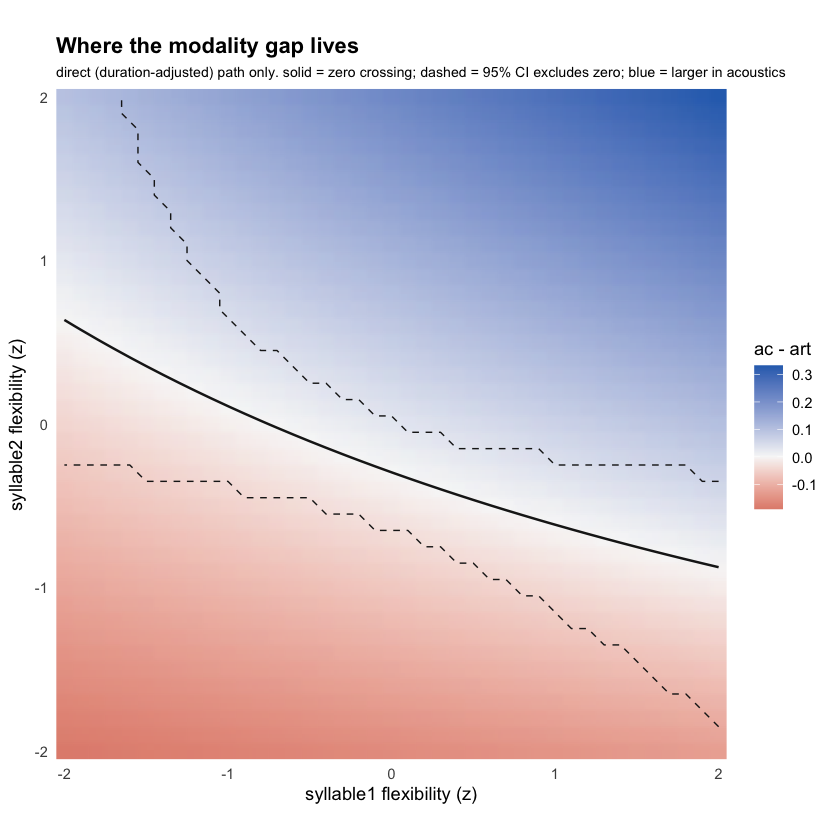

In [5]:
# ---------------------------------------------------------------------------
# 4. The surface
#
# A 41 x 41 grid is 1,681 points x 2 modalities. Raise N_GRID for a smoother
# picture at linear cost. The gap is exactly bilinear in (f1, f2) --
#
#   gap(f1,f2) = b[s:mod] + b[s:mod:f1]*f1 + b[s:mod:f2]*f2
#                         + b[s:mod:f1:f2]*f1*f2
#
# -- so a coarse grid loses nothing but the smoothness of the contour lines.
# ---------------------------------------------------------------------------

N_GRID <- 41
f1 <- seq(-2, 2, length.out = N_GRID)
f2 <- seq(-2, 2, length.out = N_GRID)

surface <- emtrends(model, ~ modality | u1_flexibility * u2_flexibility,
                    var = "bigram_surprisal",
                    at = list(u1_flexibility = f1, u2_flexibility = f2),
                    lmer.df = "asymptotic") %>%
  pairs(reverse = TRUE) %>%
  summary(infer = c(TRUE, TRUE)) %>%
  as.data.frame() %>%
  mutate(z = estimate / SE,
         sure = abs(z) > qnorm(0.975))    # 95% CI excludes zero

# Note this is not the Bayesian pd the trivariate figure uses. There the
# dashed line is "95% of the posterior is on one side of zero"; here it is
# "the 95% Wald interval excludes zero". They answer the same question and
# will usually agree, but say which one a figure shows.

INK  <- "#1b1b1b"
p <- ggplot(surface, aes(u1_flexibility, u2_flexibility)) +
  geom_raster(aes(fill = estimate), interpolate = TRUE) +
  geom_contour(aes(z = estimate), breaks = 0,
               colour = INK, linewidth = 0.7) +
  geom_contour(aes(z = as.numeric(sure)), breaks = 0.5,
               colour = INK, linewidth = 0.4, linetype = "dashed") +
  scale_fill_gradient2(low = "#c0392b", mid = "#f7f7f7", high = "#2c6fbb",
                       midpoint = 0, name = "ac - art") +
  scale_x_continuous(expand = c(0, 0)) +
  scale_y_continuous(expand = c(0, 0)) +
  coord_fixed() +
  labs(title = "Where the modality gap lives",
       subtitle = paste("direct (duration-adjusted) path only.",
                        "solid = zero crossing; dashed = 95% CI excludes zero;",
                        "blue = larger in acoustics"),
       x = paste0(u, "1 flexibility (z)"),
       y = paste0(u, "2 flexibility (z)")) +
  theme_minimal(base_size = 11) +
  theme(panel.grid = element_blank(),
        plot.title = element_text(face = "bold"),
        plot.subtitle = element_text(size = 8.5))

print(p)
ggsave("modality_gap.png", p, width = 6.5, height = 5.2, dpi = 200)

cat("\nrange of the gap over the grid: ",
    sprintf("%.3f to %.3f", min(surface$estimate), max(surface$estimate)),
    "\nshare of the plane where the sign is certain: ",
    sprintf("%.0f%%", 100 * mean(surface$sure)), "\n")


In [6]:
# ===========================================================================
# 5. The three marginal surprisal effects
#
#      overall   averaged over both modalities
#      ac        within acoustics
#      art       within articulation
#
# "Marginalised over duration and frequency" is automatic: neither interacts
# with surprisal, so neither appears in the slope. The slope is
#
#      d dist / d surprisal  =  b_s + b_sm*[mod]
#                             + (b_s1 + b_sm1*[mod]) * f1
#                             + (b_s2 + b_sm2*[mod]) * f2
#                             + (b_s12 + b_sm12*[mod]) * f1 * f2
#
# so only modality and the two flexibilities matter.
#
# That leaves a genuine choice, and the two answers are not the same:
#
#   AT THE CENTRE    set f1 = f2 = 0. Since both are z-scored, this is the
#                    slope for an average-flexibility pair.
#
#   OVER THE DATA    average the slope across the flexibility values that
#                    actually occur. Because the last term is bilinear, this
#                    equals the centre value plus b_s12 * E[f1*f2], and
#                    E[f1*f2] = cov(f1, f2), which is NOT zero -- phone1 and
#                    phone2 flexibility are correlated across real bigrams.
#
# The second is what "marginalised" usually means, so it is reported first,
# with the centre value beside it. If they disagree much, the bilinear term
# is doing real work and the figure in section 4 is the honest summary rather
# than any single number.
#
# Both modality-specific slopes are averaged over the SAME flexibility
# distribution (every token, with modality set to each level in turn), so the
# two are comparable and the overall is their unweighted mean. Weighting by
# how many rows each modality actually has would make BEUS's 4,001
# articulatory-only pairs tilt the average.
# ===========================================================================

marginal_slopes <- function(model, data, svar = "bigram_surprisal",
                            modvar = "modality", h = 1e-4) {

  tt <- delete.response(terms(model, fixed.only = TRUE))
  b  <- lme4::fixef(model)
  V  <- as.matrix(vcov(model))

  # numeric derivative of the fixed-effect design w.r.t. surprisal, averaged
  # over rows. Exact for any h, because the predictor is linear in surprisal.
  deriv_contrast <- function(d) {
    d0 <- d; d1 <- d
    d1[[svar]] <- d1[[svar]] + h
    X0 <- model.matrix(tt, d0)
    X1 <- model.matrix(tt, d1)
    stopifnot(identical(colnames(X0), names(b)))   # design must match the fit
    colMeans((X1 - X0) / h)
  }

  lev <- levels(data[[modvar]])
  cs  <- lapply(lev, function(m) { d <- data; d[[modvar]] <- factor(m, levels = lev); deriv_contrast(d) })
  names(cs) <- lev
  cs[["overall"]] <- Reduce(`+`, cs) / length(lev)

  # the same, with both flexibilities pinned to zero
  centred <- data
  centred$u1_flexibility <- 0
  centred$u2_flexibility <- 0
  cs_c <- lapply(lev, function(m) { d <- centred; d[[modvar]] <- factor(m, levels = lev); deriv_contrast(d) })
  names(cs_c) <- lev
  cs_c[["overall"]] <- Reduce(`+`, cs_c) / length(lev)

  row <- function(cv, what, where) {
    est <- sum(cv * b); se <- sqrt(drop(t(cv) %*% V %*% cv))
    data.frame(effect = what, moderators = where, estimate = est, SE = se,
               lower = est - qnorm(.975) * se, upper = est + qnorm(.975) * se,
               z = est / se, p = 2 * pnorm(-abs(est / se)))
  }

  out <- rbind(
    do.call(rbind, lapply(c("overall", lev), function(k) row(cs[[k]],   k, "averaged over the data"))),
    do.call(rbind, lapply(c("overall", lev), function(k) row(cs_c[[k]], k, "at flex1 = flex2 = 0"))))

  # and the gap, both ways, with the correct SE for a difference
  gap <- function(cl) { cv <- cl[["ac"]] - cl[["art"]]; cv }
  out <- rbind(out,
               row(gap(cs),   "ac - art", "averaged over the data"),
               row(gap(cs_c), "ac - art", "at flex1 = flex2 = 0"))
  rownames(out) <- NULL
  out
}

dat_used <- model.frame(model)
res <- marginal_slopes(model, dat_used)
print(within(res, { estimate <- round(estimate, 4); SE <- round(SE, 4)
                    lower <- round(lower, 4); upper <- round(upper, 4)
                    z <- round(z, 2); p <- signif(p, 3) }), row.names = FALSE)

cat("\ncov(flex1, flex2) in the fitted data: ",
    sprintf("%.3f", cov(dat_used$u1_flexibility, dat_used$u2_flexibility)),
    "\n  -> the two blocks above differ by b[surp:flex1:flex2] times this.\n",
    "  If they agree, quote either. If not, the surface is the result.\n", sep = "")

# --- cross-check with emmeans, which should match the "at 0" block ---
cat("\n--- emmeans cross-check (should equal the 'at flex1 = flex2 = 0' rows) ---\n")
et_chk <- emtrends(model, ~ modality, var = "bigram_surprisal",
                   at = list(u1_flexibility = 0, u2_flexibility = 0),
                   lmer.df = "asymptotic")
print(summary(et_chk, infer = c(TRUE, TRUE)))
print(summary(emmeans::contrast(et_chk, "pairwise", reverse = TRUE), infer = c(TRUE, TRUE)))


   effect             moderators estimate     SE   lower  upper    z        p
  overall averaged over the data   0.0565 0.0163  0.0244 0.0885 3.46 0.000548
      art averaged over the data   0.0401 0.0180  0.0048 0.0754 2.23 0.025900
       ac averaged over the data   0.0728 0.0180  0.0375 0.1081 4.04 0.000053
  overall   at flex1 = flex2 = 0   0.0558 0.0162  0.0239 0.0876 3.43 0.000593
      art   at flex1 = flex2 = 0   0.0419 0.0179  0.0068 0.0770 2.34 0.019200
       ac   at flex1 = flex2 = 0   0.0696 0.0179  0.0345 0.1047 3.89 0.000101
 ac - art averaged over the data   0.0327 0.0152  0.0029 0.0624 2.15 0.031300
 ac - art   at flex1 = flex2 = 0   0.0277 0.0151 -0.0019 0.0572 1.83 0.066800

cov(flex1, flex2) in the fitted data: -0.034
  -> the two blocks above differ by b[surp:flex1:flex2] times this.
  If they agree, quote either. If not, the surface is the result.

--- emmeans cross-check (should equal the 'at flex1 = flex2 = 0' rows) ---


NOTE: Results may be misleading due to involvement in interactions



 modality bigram_surprisal.trend     SE  df asymp.LCL asymp.UCL z.ratio p.value
 art                      0.0419 0.0179 Inf   0.00685     0.077   2.342  0.0192
 ac                       0.0696 0.0179 Inf   0.03451     0.105   3.887  0.0001

Degrees-of-freedom method: asymptotic 
Confidence level used: 0.95 
 contrast estimate     SE  df asymp.LCL asymp.UCL z.ratio p.value
 art - ac  -0.0277 0.0151 Inf   -0.0572   0.00192  -1.833  0.0668

Degrees-of-freedom method: asymptotic 
Confidence level used: 0.95 
